# Experiment 1 — First-order dynamics

This experiment evaluates how the first-order velocity time constant affects flight-plan following. Strategic and tactical deconfliction are disabled.

In [25]:
from pathlib import Path

from IPython.display import Image, Markdown, display

from musas.airspace import Airspace
from musas.algorithms import FirstOrderDynamics, WaypointGuidance
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from musas.simulation.metrics import (
    actual_distance,
    actual_flight_time,
    planned_distance,
    planned_flight_time,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_1"
FIGURE_DIRECTORY = Path("figs") / "figs_1"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

## Parameters

The table records the experiment constants and the relevant simulator defaults. Parameters marked as disabled do not affect this experiment.

| Component | Parameter | Value | Note |
|---|---|---:|---|
| Experiment | Velocity time constants, $\tau$ | $[0.0, 0.5, 1.5, 4.0]$ s | Varied parameter |
| Experiment | Simulation end | 80.0 s | Used |
| Flight plan | Priority | 0 | Default |
| Flight plan | Initial altitude | 100.0 m | Used |
| UAV | Submission time | 0.0 s | Default |
| UAV | Waypoint acceptance radius | 2.0 m | Used |
| Dynamics | Maximum acceleration | 100.0 m/s² | Used; high enough not to dominate the comparison |
| Guidance | Minimum speed | 0.0 m/s | Default |
| Guidance | Maximum speed | 14.0 m/s | Used |
| Sensor | Sensor model | PerfectSensor | UAV default |
| Airspace | Obstacles, geofences and wind zones | None | Used |
| Simulation | Strategic deconfliction | Disabled | Default when both SD algorithms are `None` |
| Simulation | Tactical deconfliction | Disabled | Default |
| Simulation | Tracking | Disabled | Default |
| Simulation | Network delay | 0.0 s | Default |
| Simulation | Flight-update interval | 0.1 s | Default |
| Simulation | Trajectory-record interval | 0.2 s | Default |
| Simulation | Report interval | 0.5 s | Default; inactive without tracking |
| Simulation | History window | 6 reports | Default; inactive |
| Simulation | Prediction horizon | 10 steps | Default; inactive |
| Simulation | Prediction step | 0.5 s | Default; inactive |
| Simulation | Tactical-assessment interval | 1.0 s | Default; inactive |
| Simulation | Collision distance | 1.0 m | Default |
| Simulation | Processing times | 0.0 s | Default |
| Dataset | Flush interval | 10.0 s | Default |
| Dataset | Keep history in memory | True | Default |
| Dataset | Overwrite existing file | True | Used |
| Network events | Message types logged | None | Used |
| Visualization | View | XY | Used |
| Visualization | Frame step | 0.5 s | Used |
| Visualization | Figure size | $(8.0, 5.5)$ in | Default |
| Visualization | Static-image DPI | 300 | Default |
| Visualization | Animation FPS / DPI | 10 / 120 | Used / default |
| Visualization | Real trajectory / flight plan | Shown / shown | Used |
| Visualization | Tracks, reports and airspace layers | Hidden | Used |
| Visualization | Legend / grid / timestamp | Shown / shown / shown | Defaults |

In [26]:
TIME_CONSTANTS = (0.0, 0.5, 1.5, 4.0)
SIMULATION_END = 80.0
MAX_ACCELERATION = 100.0
MAX_SPEED = 14.0
WAYPOINT_ACCEPTANCE_RADIUS = 2.0

def create_flight_plan():
    return FlightPlan(
        waypoint_list=[
            Waypoint(0.0, 0.0, 100.0, 2.0),
            Waypoint(60.0, 0.0, 100.0, 10.0),
            Waypoint(100.0, 40.0, 100.0, 18.0),
            Waypoint(60.0, 80.0, 100.0, 26.0),
            Waypoint(0.0, 80.0, 100.0, 34.0),
            Waypoint(-40.0, 40.0, 100.0, 42.0),
            Waypoint(0.0, 0.0, 100.0, 50.0),
        ],
        priority=0,
    )

## Run the cases

Only `velocity_time_constant` changes between executions. Each case is stored in its own SQLite dataset.

In [27]:
def tau_label(tau):
    return str(tau).replace(".", "_")

def run_case(tau):
    dataset_path = OUTPUT_DIRECTORY / f"tau_{tau_label(tau)}.sqlite"
    simulation = Simulation(
        airspace=Airspace(),
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": 1,
            "velocity_time_constant": tau,
        },
        overwrite_dataset=True,
    )
    simulation.add_uav(
        name="UAV 1",
        flight_plan=create_flight_plan(),
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=MAX_ACCELERATION,
            velocity_time_constant=tau,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=MAX_SPEED,
        ),
        waypoint_acceptance_radius=WAYPOINT_ACCEPTANCE_RADIUS,
    )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {tau: run_case(tau) for tau in TIME_CONSTANTS}
dataset_paths

{0.0: PosixPath('outputs/output_1/tau_0_0.sqlite'),
 0.5: PosixPath('outputs/output_1/tau_0_5.sqlite'),
 1.5: PosixPath('outputs/output_1/tau_1_5.sqlite'),
 4.0: PosixPath('outputs/output_1/tau_4_0.sqlite')}

## Results

The following table uses the metrics already provided by MUSAS.

In [28]:
rows = []
for tau, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        values = (
            planned_distance(dataset, "UAV 1"),
            actual_distance(dataset, "UAV 1"),
            planned_flight_time(dataset, "UAV 1"),
            actual_flight_time(dataset, "UAV 1"),
        )
    rows.append((tau, *values))

table = [
    "| $\tau$ (s) | Planned distance | Executed distance | Planned time | Executed time |",
    "|---:|---:|---:|---:|---:|",
]
for tau, planned_d, actual_d, planned_t, actual_t in rows:
    actual_d_text = "Not completed" if actual_d is None else f"{actual_d:.2f}"
    actual_t_text = "Not completed" if actual_t is None else f"{actual_t:.2f}"
    table.append(
        f"| {tau:.1f} | {planned_d:.2f} | {actual_d_text} | "
        f"{planned_t:.2f} | {actual_t_text} |"
    )
display(Markdown("\n".join(table)))

| $	au$ (s) | Planned distance | Executed distance | Planned time | Executed time |
|---:|---:|---:|---:|---:|
| 0.0 | 346.27 | 339.17 | 48.00 | 47.80 |
| 0.5 | 346.27 | 344.82 | 48.00 | 47.80 |
| 1.5 | 346.27 | 356.57 | 48.00 | 47.90 |
| 4.0 | 346.27 | 535.78 | 48.00 | 76.40 |

## Figures and animations

The built-in visualization functions show the planned and executed trajectories using identical axes and layers for every case.

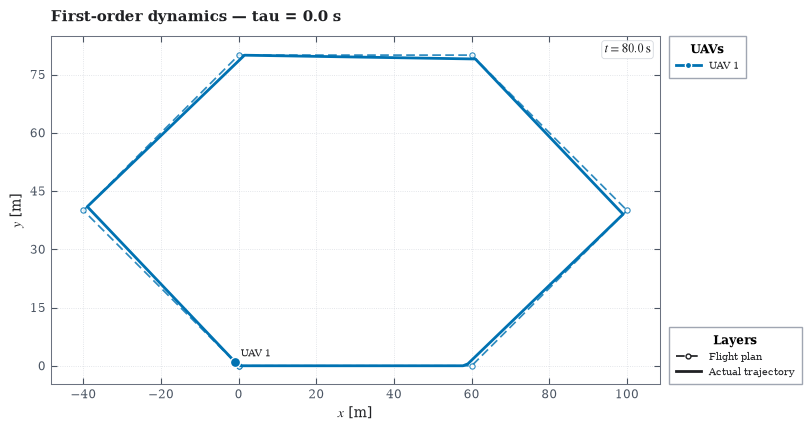

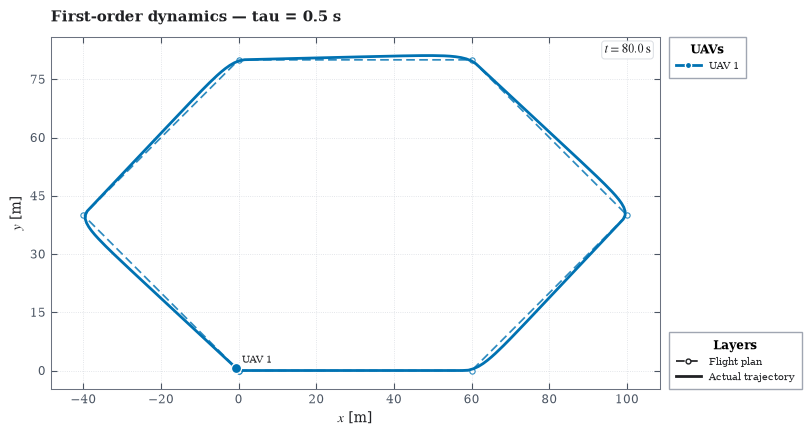

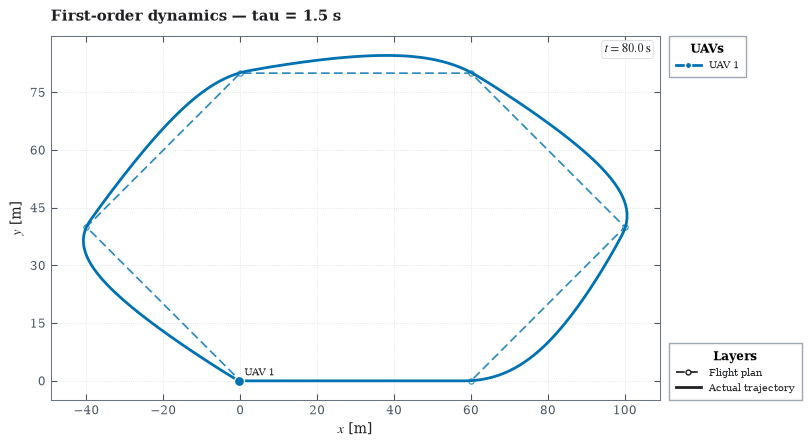

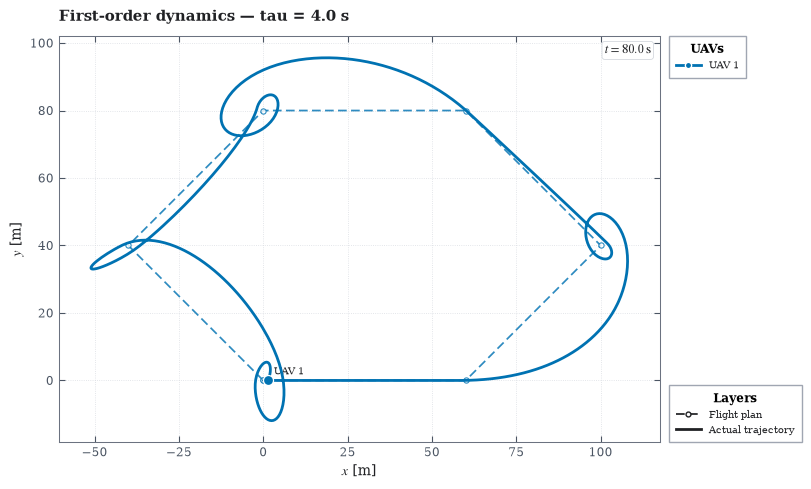

Figures: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/experiments/figs/figs_1


In [29]:
def visualization_config(tau):
    return VisualizationConfig(
        uav_names=("UAV 1",),
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_tracks=False,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=False,
        frame_step=0.5,
        title=f"First-order dynamics — tau = {tau:.1f} s",
        spatial_unit="m",
    )

figure_paths = {}
animation_paths = {}
for tau, dataset_path in dataset_paths.items():
    label = tau_label(tau)
    figure_path = FIGURE_DIRECTORY / f"tau_{label}.png"
    animation_path = FIGURE_DIRECTORY / f"tau_{label}.gif"
    config = visualization_config(tau)
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=config,
        timestamp=SIMULATION_END,
        output_path=figure_path,
    )
    display(figure)
    animate_dataset(
        dataset_path=dataset_path,
        config=config,
        output_path=animation_path,
        fps=10.0,
    )
    figure_paths[tau] = figure_path
    animation_paths[tau] = animation_path

print("Figures:", FIGURE_DIRECTORY.resolve())

### $	au = 0.0$ s

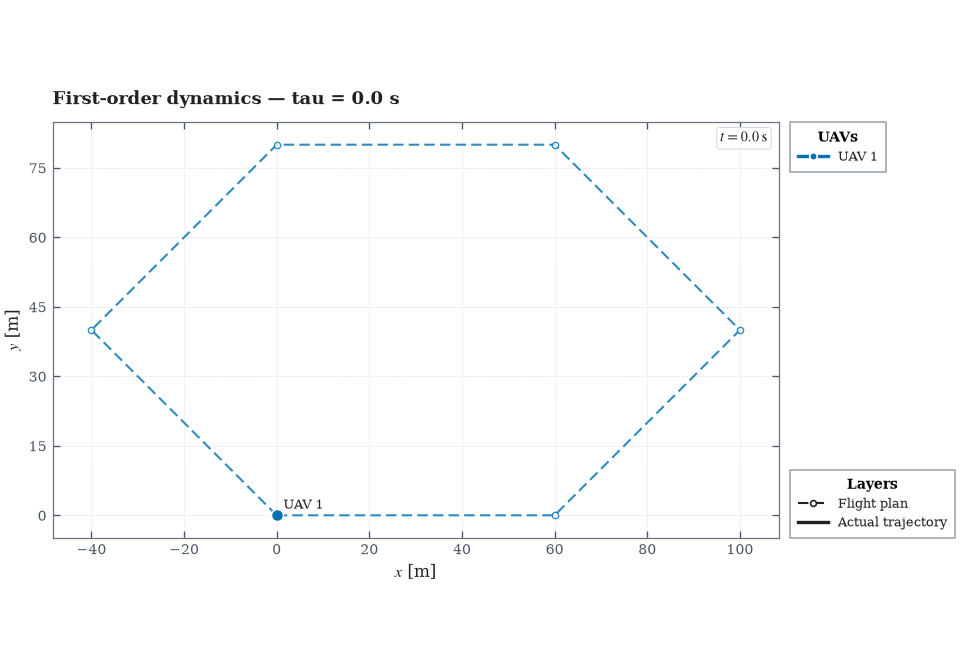

### $	au = 0.5$ s

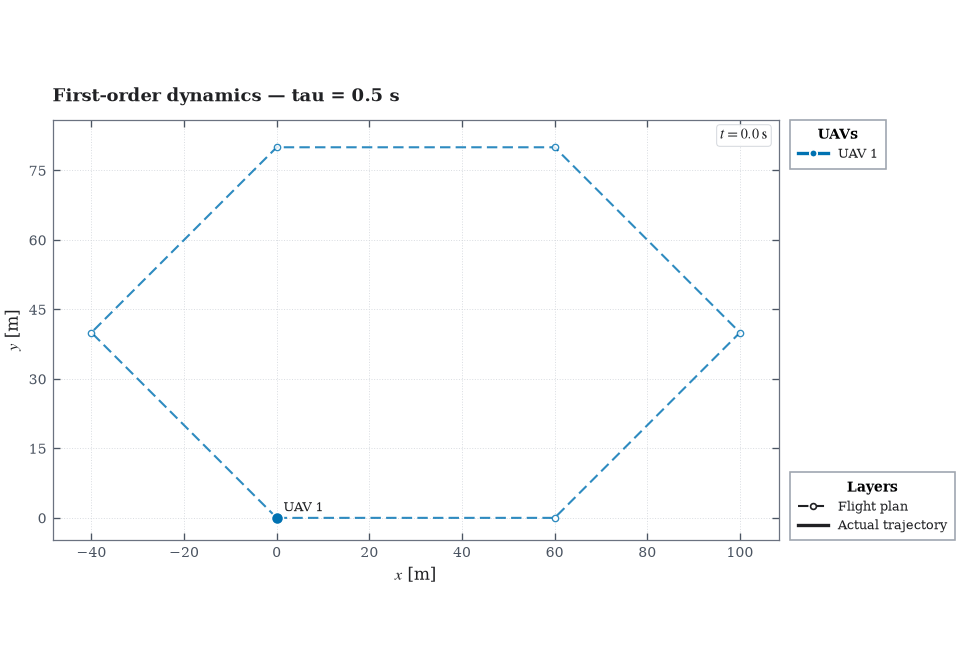

### $	au = 1.5$ s

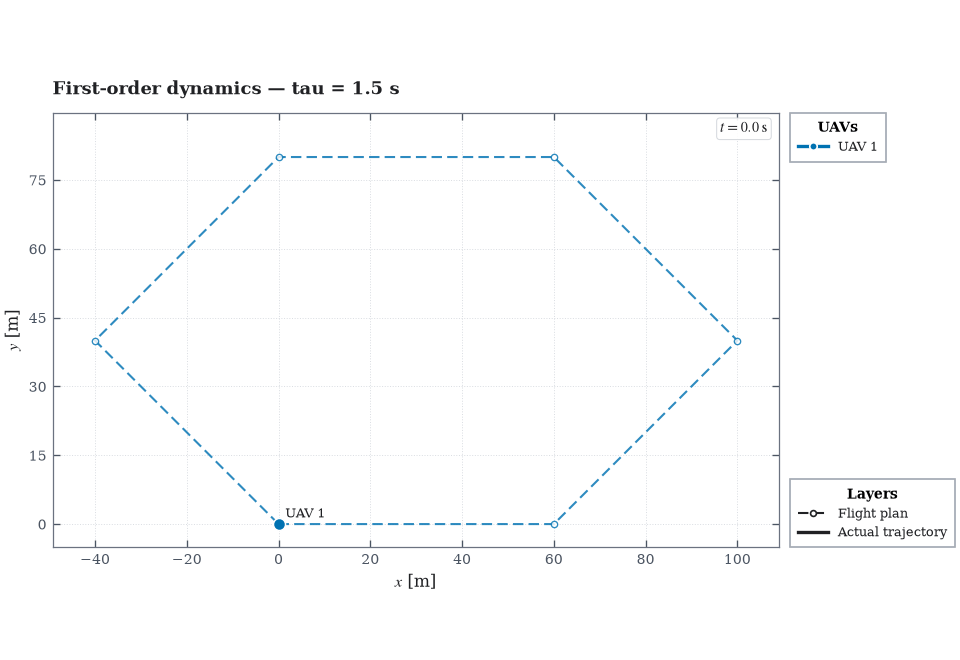

### $	au = 4.0$ s

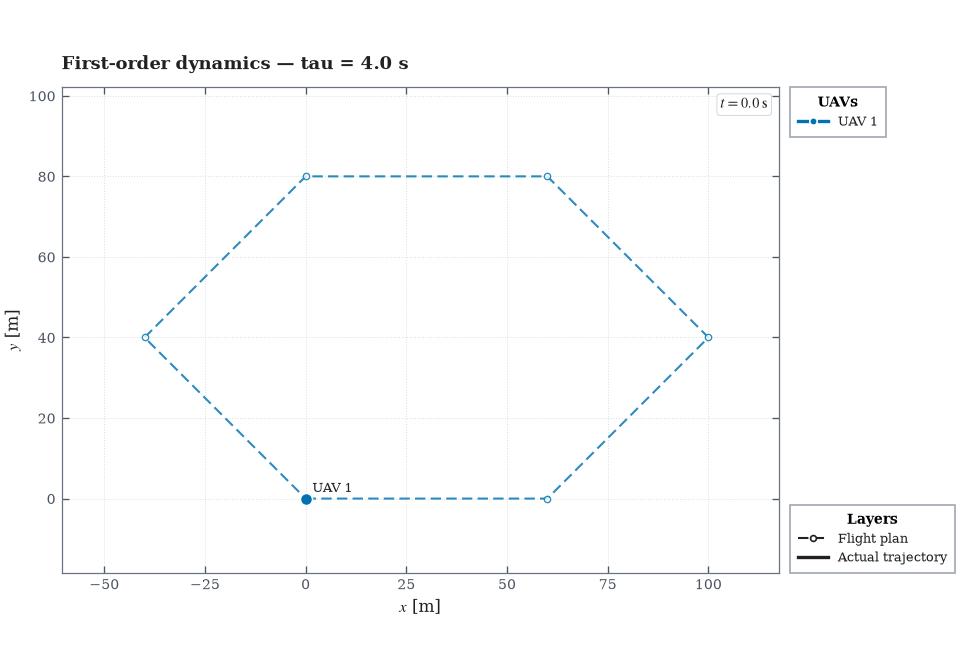

In [30]:
for tau, animation_path in animation_paths.items():
    display(Markdown(f"### $\tau = {tau:.1f}$ s"))
    display(Image(filename=animation_path))